# 04. Exception queue

**Business question:** what does the reviewer actually work on? The workflow's output for people is a single CSV
queue: one row per NEEDS_REVIEW or INVALID record, with the raw values, the standardised values, why it is in the
queue, a suggested fix where one exists, a priority and a recommended action.

In [1]:
import sys
sys.path.append('../src')
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
pd.set_option('display.width', 140)
pd.set_option('display.max_columns', 20)
pd.set_option('display.max_colwidth', 60)
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False})
FIG = '../reports/figures'
from reference import load_zip_reference
raw = pd.read_csv('../data/raw/address_records.csv', dtype=str, keep_default_na=False)
ref = load_zip_reference('../data/raw/zip_reference.csv')
res = pd.read_csv('../data/processed/workflow_results.csv', dtype=str, keep_default_na=False)

In [2]:
q = res[res.status.isin(['NEEDS_REVIEW', 'INVALID'])].merge(
    raw[['record_id', 'first_name', 'last_name', 'address_line1', 'address_line2', 'city', 'state', 'zip',
         'source_system', 'created_at']], on='record_id')
print(f'{len(q):,} records in the queue ({len(q) / len(res):.1%} of {len(res):,})')
q.reasons.str.split('|').explode().value_counts().to_frame('queue records carrying this reason code')

3,591 records in the queue (7.2% of 49,920)


,queue records carrying this reason code
reasons,
MULTIPLE_ZIPS,1405
CITY_ZIP_CONFLICT,878
POSSIBLE_DUPLICATE,496
MISSING_LINE1,308
NO_HOUSE_NUMBER,277
UNLOCATABLE,244
UNIT_PARSED,171
SUFFIX_STANDARDISED,164
CITY_FUZZY_CORRECTED,102


## 1. Priority and action
* **P1** (INVALID): cannot be mailed at all; contact the patient.
* **P2** (conflicting location: city vs ZIP, state vs ZIP, unknown state): one of two fields is wrong; check the
  source document or call.
* **P3** (resolvable by a lookup: several ZIPs for the city, ambiguous or unknown city, missing house number).
* **P4** (possible duplicate): merge decision only; the address itself is fine.

In [3]:
PRIORITY = {'MISSING_LINE1': ('P1', 'Contact patient for full street address'),
            'UNLOCATABLE': ('P1', 'Contact patient: no ZIP and no city on file'),
            'CITY_ZIP_CONFLICT': ('P2', 'Confirm city or ZIP against intake document'),
            'STATE_ZIP_CONFLICT': ('P2', 'Confirm state or ZIP against intake document'),
            'STATE_UNKNOWN': ('P2', 'Confirm state'),
            'MULTIPLE_ZIPS': ('P3', 'Pick ZIP from the listed candidates using the street'),
            'AMBIGUOUS_CITY': ('P3', 'Choose between close city matches'),
            'CITY_NOT_FOUND': ('P3', 'Look up city spelling'),
            'NO_HOUSE_NUMBER': ('P3', 'Add house number from intake document'),
            'POSSIBLE_DUPLICATE': ('P4', 'Decide merge with the suggested master record')}
# primary reason = the most urgent reason a record carries
q['primary_reason'] = q.reasons.str.split('|').apply(lambda rs: min((r for r in rs if r in PRIORITY), key=lambda r: PRIORITY[r][0]))
q['priority'] = q.primary_reason.map(lambda r: PRIORITY[r][0])
q['recommended_action'] = q.primary_reason.map(lambda r: PRIORITY[r][1])
q = q.sort_values(['priority', 'created_at']).reset_index(drop=True)
pd.crosstab(q.primary_reason, q.priority)

priority,P1,P2,P3,P4
primary_reason,,,,
CITY_NOT_FOUND,0,0,13,0
CITY_ZIP_CONFLICT,0,871,0,0
MISSING_LINE1,308,0,0,0
MULTIPLE_ZIPS,0,0,1388,0
NO_HOUSE_NUMBER,0,0,269,0
POSSIBLE_DUPLICATE,0,0,0,496
STATE_ZIP_CONFLICT,0,6,0,0
UNLOCATABLE,240,0,0,0


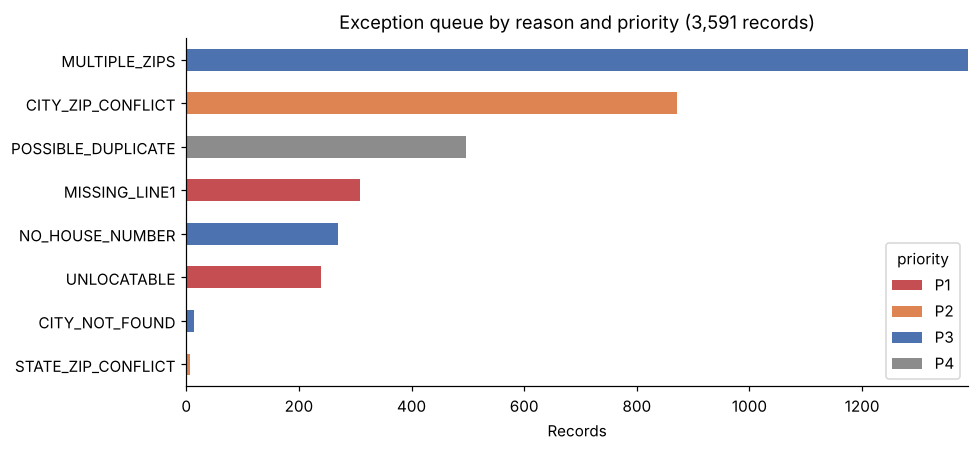

In [4]:
fig, ax = plt.subplots(figsize=(9, 4.2))
counts = q.groupby(['primary_reason', 'priority']).size().unstack(fill_value=0)
counts = counts.loc[counts.sum(axis=1).sort_values().index]
counts.plot.barh(stacked=True, ax=ax, color={'P1': '#C44E52', 'P2': '#DD8452', 'P3': '#4C72B0', 'P4': '#8C8C8C'})
ax.set_title(f'Exception queue by reason and priority ({len(q):,} records)')
ax.set_xlabel('Records'); ax.set_ylabel('')
plt.tight_layout(); plt.savefig(f'{FIG}/exception_queue.png', bbox_inches='tight'); plt.show()

## 2. Queue file

In [5]:
cols = ['priority', 'record_id', 'status', 'primary_reason', 'reasons', 'recommended_action', 'suggestion',
        'first_name', 'last_name', 'address_line1', 'address_line2', 'city', 'state', 'zip',
        'final_line1', 'final_line2', 'final_city', 'final_state', 'final_zip', 'possible_duplicate_of',
        'source_system', 'created_at']
queue = q[cols].rename(columns={'address_line1': 'raw_line1', 'address_line2': 'raw_line2', 'city': 'raw_city',
                                'state': 'raw_state', 'zip': 'raw_zip', 'final_line1': 'std_line1',
                                'final_line2': 'std_line2', 'final_city': 'std_city', 'final_state': 'std_state',
                                'final_zip': 'std_zip'})
queue.to_csv('../data/processed/exception_queue.csv', index=False)
print(f'wrote ../data/processed/exception_queue.csv: {len(queue):,} rows, {queue.shape[1]} columns')
queue.groupby('priority').size().to_frame('records')

wrote ../data/processed/exception_queue.csv: 3,591 rows, 22 columns


,records
priority,
P1,548
P2,877
P3,1670
P4,496


In [6]:
queue.groupby('primary_reason').head(1)[['priority', 'record_id', 'primary_reason', 'raw_line1', 'raw_city', 'raw_state',
                                          'raw_zip', 'suggestion', 'recommended_action']]

,priority,record_id,primary_reason,raw_line1,raw_city,raw_state,raw_zip,suggestion,recommended_action
0,P1,R000061,MISSING_LINE1,,FOXBROOK,TX,78318,,Contact patient for full street address
3,P1,R000349,UNLOCATABLE,3997 Dogwood St,,NC,,,Contact patient: no ZIP and no city on file
548,P2,R000000,CITY_ZIP_CONFLICT,828 Lake Rd,Riverwood,NY,15222,"ZIP 15222 is LINBURG, NY",Confirm city or ZIP against intake document
698,P2,R009249,STATE_ZIP_CONFLICT,7781 Aspen Cir,,MI,80784,"ZIP 80784 is NORTHRIDGE, CO",Confirm state or ZIP against intake document
1425,P3,R000058,MULTIPLE_ZIPS,4401 S Prospect Rd,Fairburg,NC,,"FAIRBURG, NC has ZIPs 22045, 22072, 24902, 24913",Pick ZIP from the listed candidates using the street
1428,P3,R000221,NO_HOUSE_NUMBER,Forest Dr,Fairwick,GA,37250,,Add house number from intake document
1455,P3,R001112,CITY_NOT_FOUND,Post Office Box 6674,Fyrmint,ME,,,Look up city spelling
3095,P4,R049661,POSSIBLE_DUPLICATE,1195 Franklin Dr,Riverwood,CA,93641,"same address as R000780, similar name",Decide merge with the suggested master record


## 3. How useful are the suggestions?
For queue records the ground truth shows whether the suggested ZIP/city already contains the right answer, i.e. how
often a reviewer only needs to confirm.

In [7]:
gt = pd.read_csv('../data/raw/address_ground_truth.csv', dtype=str, keep_default_na=False)
qq = queue.merge(gt, on='record_id')
is_dup = qq.primary_reason == 'POSSIBLE_DUPLICATE'
has_sugg = (qq.suggestion != '') & ~is_dup
qq['suggestion_contains_truth'] = [(t_zip in s) or (t_city in s.upper())
                                   for s, t_zip, t_city in zip(qq.suggestion, qq.true_zip, qq.true_city)]
print(f'address rows with a location suggestion: {has_sugg.sum():,} of {(~is_dup).sum():,}')
print(f'possible duplicates whose suggested master is the true original: '
      f'{(qq[is_dup].possible_duplicate_of == qq[is_dup].duplicate_of).mean():.1%} of {is_dup.sum()}')
qq[has_sugg].groupby('primary_reason').agg(rows=('record_id', 'count'),
    suggestion_contains_true_value=('suggestion_contains_truth', 'mean')).round(3)

address rows with a location suggestion: 2,290 of 3,095
possible duplicates whose suggested master is the true original: 96.8% of 496


,rows,suggestion_contains_true_value
primary_reason,,
CITY_ZIP_CONFLICT,871,0.917
MISSING_LINE1,19,1.000
MULTIPLE_ZIPS,1388,1.000
NO_HOUSE_NUMBER,6,1.000
STATE_ZIP_CONFLICT,6,1.000


In [8]:
daily = queue.assign(day=pd.to_datetime(queue.created_at).dt.date).groupby('day').size()
print(f'queue arrival: mean {daily.mean():.1f} records/day, 95th percentile {daily.quantile(.95):.0f}; '
      f'at 4 minutes per record that is {daily.mean() * 4 / 60:.1f} analyst hours per day')

queue arrival: mean 13.3 records/day, 95th percentile 19; at 4 minutes per record that is 0.9 analyst hours per day


## Findings

* The queue file `data/processed/exception_queue.csv` has **3,591 rows and 22 columns** (7.2% of records):
  **548 P1** (INVALID, patient outreach), **877 P2** (city/ZIP or state/ZIP conflicts), **1,670 P3** (lookups:
  several ZIPs for the city, missing house number, unknown city) and **496 P4** (possible duplicates).
* By primary reason: several possible ZIPs 1,388, city/ZIP conflict 871, possible duplicate 496, missing street
  line 308, no house number 269, no ZIP and no city 240, unknown city 13, state/ZIP conflict 6.
* 2,290 of the 3,095 address rows come with a suggestion. For several-ZIP cases the candidate list always contains
  the true ZIP, and for city/ZIP conflicts the suggested city is right 91.7% of the time, so most reviews are a
  confirmation rather than research. For possible duplicates the suggested master is the true original in 96.8%
  of cases.
* The queue grows by about 13 records a day, under one analyst hour a day at 4 minutes per record.